<a href="https://colab.research.google.com/github/group6aiml-hub/NIDS_AInML/blob/main/notebooks/07_Neural_Network_Hubert.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Template: load data

Copy this notebook (**File → Save a copy in Drive**), rename it to `07a_<your model>.ipynb`
and build your model below. See `src/data.py` for what `d` contains and the rules in the README.

#### 1. Setup og Load data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q imbalanced-learn
!rm -rf /content/NIDS_AInML
!git clone -q https://github.com/group6aiml-hub/NIDS_AInML.git
import sys; sys.path.append('/content/NIDS_AInML/src')
from data import last_data

d = last_data()
print(d['X_tr'].shape, d['X_val'].shape)   # expected: (86192, 41) (21548, 41)
print('Classes:', list(d['le'].classes_))

print("Features: ", d['X_tr'])

### Local data loading, for faster performance

In [20]:
import sys
from pathlib import Path
import pandas as pd

repo_root = Path.cwd().resolve().parent

sys.path.insert(0, str(repo_root))
sys.path.insert(0, str(repo_root / "src"))

from data import last_data


data_dir = repo_root / "datasets"
d = last_data(str(data_dir) + "/")



print(d['X_tr'].shape, d['X_val'].shape)   # expected: (86192, 41) (21548, 41)
print('Classes:', list(d['le'].classes_))

print("Features: ", d['X_tr'])

processor = d['lag_preprocess']()

x_train = d['X_tr']
y_train = d['y_tr_mc']
x_val = d['X_val']
y_val = d['y_val_mc']

(86192, 41) (21548, 41)
Classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
Features:               dur  proto service state  spkts  dpkts  sbytes  dbytes  \
44435   0.000002    udp       -   INT      2      0     104       0   
3461    0.001064    udp     dns   CON      2      2     146     178   
93673   0.000011    udp       -   INT      2      0     168       0   
102977  0.639900    tcp       -   FIN     10      8     564     354   
26050   0.005607    tcp       -   FIN     22     24    2054    2478   
...          ...    ...     ...   ...    ...    ...     ...     ...   
79743   0.407582    tcp    http   FIN     10      8     824    1480   
88710   0.000009  other       -   INT      2      0     200       0   
28364   0.001540    udp       -   CON      4      4     520     304   
104347  0.742956    tcp     ftp   FIN     14     12     798     682   
8369    0.037877    tcp       -   FIN     68     70    4014

# Hyperparameter Tuning

Analysis of activation functions, optimizers, and learning rate

## Comparison of Activation functions

In [35]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score



# we can use this for the comparison of different activation functions, etc
def Create_Pipeline(activation_func, Xtrain=x_train, Ytrain=y_train, preprocessor=processor):
  prediction_Pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', MLPClassifier(activation=activation_func))
  ])

  prediction_Pipeline.fit(Xtrain, Ytrain)

  def Predict(pipeline=prediction_Pipeline, Xtest=x_val, Ytest=y_val):
    prediction = pipeline.predict(Xtest)
    accuracy = pipeline.score(Xtest, Ytest)

    accuracy = prediction_Pipeline.score(x_val, y_val)
    percentage = accuracy_score(y_val, prediction) * 100

    print("Accurarcy of neural network: ", accuracy)
    print("Percentage: ", percentage,"%")

  Predict()

  return prediction_Pipeline


print("RELU: ")
RELU_MLP = Create_Pipeline('relu')

print("Tanh: ")
TanH_MLP = Create_Pipeline('tanh')

print("Sigmoid: ")
Sigmoid_MLP = Create_Pipeline('logistic')

print("Identity: ")
Identity_MLP = Create_Pipeline('identity')

# prediction_Pipeline.fit(x_train, y_train)
# predictions = prediction_Pipeline.predict(x_val)


RELU: 


C:\Users\huber\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Accurarcy of neural network:  0.8046222387228513
Percentage:  80.46222387228514 %
Tanh: 


C:\Users\huber\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Accurarcy of neural network:  0.8026266938927047
Percentage:  80.26266938927047 %
Sigmoid: 


C:\Users\huber\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Accurarcy of neural network:  0.8038797104139596
Percentage:  80.38797104139596 %
Identity: 
Accurarcy of neural network:  0.75914237980323
Percentage:  75.914237980323 %


## Comparison between different Optimizers: Adam, SGF(Stochastic Gradient Finder), LBFGS

Since ReLU provided the highest accuracy(on the first few attempts) in the prior block, we'll select it as the activation function for all the new models


In [34]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


processor = d['lag_preprocess']()

x_train = d['X_tr']
y_train = d['y_tr_mc']
x_val = d['X_val']
y_val = d['y_val_mc']


def Create_Pipeline2(Solver, Xtrain=x_train, Ytrain=y_train, preprocessor=processor):
  prediction_Pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', MLPClassifier(solver=Solver, activation="relu"))
  ])

  prediction_Pipeline.fit(Xtrain, Ytrain)

  def Predict(pipeline=prediction_Pipeline, Xtest=x_val, Ytest=y_val):
    prediction = pipeline.predict(Xtest)
    accuracy = pipeline.score(Xtest, Ytest)

    accuracy = prediction_Pipeline.score(x_val, y_val)
    percentage = accuracy_score(y_val, prediction) * 100

    print("Accurarcy of neural network: ", accuracy)
    print("Percentage: ", percentage,"%")

  Predict()

  return prediction_Pipeline

print("Adam: ")
Adam_MLP = Create_Pipeline2('adam')

print("SGD: ")
SGD_MLP = Create_Pipeline2('sgd')

print("LBFGS: ")
LBFGS_MLP = Create_Pipeline2('lbfgs')

Adam: 


C:\Users\huber\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Accurarcy of neural network:  0.8056432151475775
Percentage:  80.56432151475775 %
SGD: 


C:\Users\huber\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Accurarcy of neural network:  0.7910710970855764
Percentage:  79.10710970855764 %
LBFGS: 
Accurarcy of neural network:  0.7971969556339336
Percentage:  79.71969556339336 %


C:\Users\huber\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


## Analysis of Learing rate for Multi-Class prediction

### Learing Rate:

- aimed purely at SGD(Stochastic Gradient Descent) because the Adam solver adjusts learning rate based on previous performance(it's also computationally expensive)
- used the default 200 epochs

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Learning rate: 0.00010 | Validation accuracy: 75.90% | Epochs: 200


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Learning rate: 0.00019 | Validation accuracy: 76.80% | Epochs: 200


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


...

Learning rate: 0.02848 | Validation accuracy: 80.10% | Epochs: 200


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Learning rate: 0.05337 | Validation accuracy: 80.29% | Epochs: 200


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Learning rate: 0.10000 | Validation accuracy: 79.93% | Epochs: 200


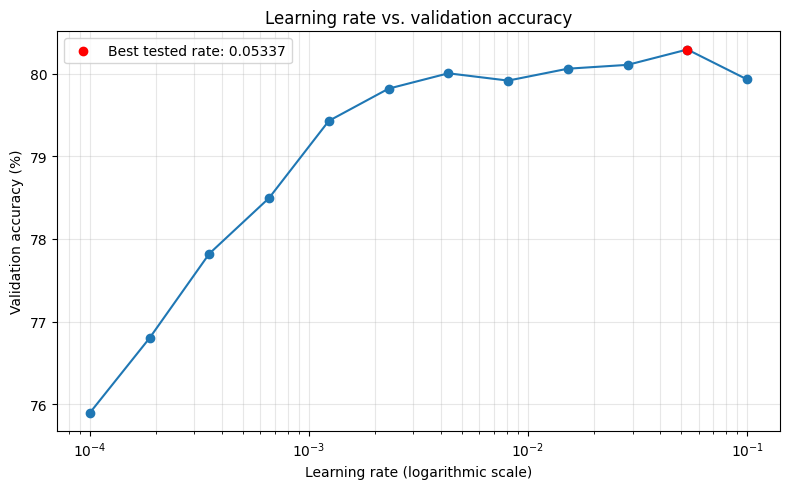


Best tested learning rate: 0.05337
Validation accuracy: 80.29%


In [6]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score



x_train = d["X_tr"]
y_train = d["y_tr_mc"]
x_val = d["X_val"]
y_val = d["y_val_mc"]

# Fit preprocessing only on training data.
processor = d["lag_preprocess"]()

x_train_processed = processor.fit_transform(x_train, y_train)
x_val_processed = processor.transform(x_val)

# 12 values from 0.0001 to 0.1, spaced logarithmically.
selected_rates = np.logspace(-4, -1, 12)
accuracies = []

for rate in selected_rates:
    # Start from a fresh model for every learning rate.
    model = MLPClassifier(
        hidden_layer_sizes=(100,),
        activation="relu",
        solver="sgd",
        learning_rate="constant",
        learning_rate_init=float(rate),
        max_iter=200,
        random_state=42,
    )

    model.fit(x_train_processed, y_train)

    accuracy = model.score(x_val_processed, y_val) * 100
    accuracies.append(accuracy)

    print(
        f"Learning rate: {rate:.5f} | "
        f"Validation accuracy: {accuracy:.2f}% | "
        f"Epochs: {model.n_iter_}"
    )

accuracies = np.array(accuracies)

best_index = np.argmax(accuracies)
best_rate = selected_rates[best_index]

fig, ax = plt.subplots(figsize=(8, 5))

ax.semilogx(selected_rates, accuracies, marker="o")
ax.scatter(
    best_rate,
    accuracies[best_index],
    color="red",
    zorder=3,
    label=f"Best tested rate: {best_rate:.5f}",
)

ax.set(
    xlabel="Learning rate (logarithmic scale)",
    ylabel="Validation accuracy (%)",
    title="Learning rate vs. validation accuracy",
)

ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

print(
    f"\nBest tested learning rate: {best_rate:.5f}"
    f"\nValidation accuracy: {accuracies[best_index]:.2f}%"
)


# Evaluation Metrics

In [33]:
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, recall_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, LabelEncoder
from imblearn.over_sampling import SMOTE
import time
import pandas as pd

x_train = d["X_tr"]
x_val = d["X_val"]

y_train_mc = d["y_tr_mc"]
y_train_bin = d["y_tr_bin"]
y_val_mc = d["y_val_mc"]
y_val_bin = d["y_val_bin"]

print("----")

resultater = []

def test_modell(navn, lag_clf):
    """lag_clf er en funksjon som lager en NY modell hver gang den kalles."""
    rad = {'Modell': navn}

    # Binær (uten SMOTE)
    p = Pipeline([('prep', d['lag_preprocess']()), ('clf', lag_clf())])
    t = time.time(); p.fit(x_train, y_train_bin); rad['Tid binær (s)'] = round(time.time() - t, 1)
    pred = p.predict(x_val)
    
    rad['Binær macro-F1']  = f1_score(y_val_bin, pred, average='macro')
    rad['Recall angrep']   = recall_score(y_val_bin, pred)

    # Multiklasse (med SMOTE)
    p = ImbPipeline([('prep', d['lag_preprocess']()),
                     ('smote', SMOTE(sampling_strategy=d['smote_strategi'], random_state=42)),
                     ('clf', lag_clf())])
    
    t = time.time(); p.fit(x_train, y_train_mc); rad['Tid multi (s)'] = round(time.time() - t, 1)
    
    pred = p.predict(x_val)
    
    rad['Multi macro-F1'] = f1_score(y_val_mc, pred, average='macro')

    print(f'===== {navn} (multiklasse)')
    print(classification_report(y_val_mc, pred, target_names=d["le"].classes_, digits=3, zero_division=0))
    resultater.append(rad)


test_modell("Neural Network", lambda : MLPClassifier(
    activation='relu', max_iter=200, solver='sgd', 
    learning_rate_init=0.05337, random_state=42
))


----
===== Neural Network (multiklasse)
                precision    recall  f1-score   support

      Analysis      0.223     0.154     0.182       319
      Backdoor      0.184     0.808     0.300       307
           DoS      0.307     0.290     0.299       761
      Exploits      0.846     0.721     0.778      3969
       Fuzzers      0.697     0.701     0.699      3230
       Generic      0.948     0.823     0.881       836
        Normal      0.937     0.903     0.920     10378
Reconnaissance      0.789     0.767     0.778      1504
     Shellcode      0.473     0.716     0.569       218
         Worms      0.128     0.538     0.207        26

      accuracy                          0.790     21548
     macro avg      0.553     0.642     0.561     21548
  weighted avg      0.825     0.790     0.803     21548

